In [1]:
import pathlib
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


import el_hd_plasticity.two_photon as nmp
from SessionTools import two_photon as st2p

plt.rcParams['pdf.fonttype']=42

%load_ext autoreload
%autoreload 2 


%matplotlib inline


In [2]:
basedir = pathlib.Path('/media/mplitt/SSD_storage/2P_scratch/R18B05LexA_CsChrimsontdT_R60D05Gal4_jGCaMP7f/remapping_w_dark')
sess_df = pd.read_csv(basedir / 'sessions.csv')
sess_df = sess_df.iloc[:-1]
print(sess_df.columns)
sess_df['fly_id'] = [row['date']+'_'+row['fly'] +'_' + row['condition'] for _, row in sess_df.iterrows()]
sess_df['mean offset'] = [np.nan for _, row in sess_df.iterrows()]
sess_df['offset var.'] = [np.nan for _, row in sess_df.iterrows()]
sess_df['mean vec. len'] = [np.nan for _, row in sess_df.iterrows()]


figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/R18B05LexA_CsChrimsontdT_R60D05Gal4_jGCaMP7f')
figfolder.mkdir(parents=True, exist_ok=True)

Index(['date', 'fly', 'sess', 'fictrac_scan_num', 'fictrac_file', 'condition',
       'scan_type', 'post_dark', 'usable', 'notes'],
      dtype='str')


In [3]:
sess_df.head()

,date,fly,sess,fictrac_scan_num,fictrac_file,condition,scan_type,post_dark,usable,notes,fly_id,mean offset,offset var.,mean vec. len
0,22_04_2026,fly1,baseline-000,0,fictrac-20260422_101638.dat,replication,baseline,0,NaN,NaN,22_04_2026_fly1_replication,NaN,NaN,NaN
1,22_04_2026,fly1,remap_0deg-002,2,fictrac-20260422_101638.dat,replication,remap_0deg,0,NaN,NaN,22_04_2026_fly1_replication,NaN,NaN,NaN
2,22_04_2026,fly1,post_0deg-004,4,fictrac-20260422_101638.dat,replication,post_0deg,0,NaN,NaN,22_04_2026_fly1_replication,NaN,NaN,NaN
3,22_04_2026,fly1,remap_180deg_wdark-005,5,fictrac-20260422_101638.dat,replication,remap_180deg,1,NaN,NaN,22_04_2026_fly1_replication,NaN,NaN,NaN
4,22_04_2026,fly1,post_180deg_wdark-006,6,fictrac-20260422_101638.dat,replication,post_180deg,1,NaN,NaN,22_04_2026_fly1_replication,NaN,NaN,NaN


In [4]:
def load_row(row):
    outdir = pathlib.PurePath( basedir / row['condition'] / row['date'] / row['fly'] / row['sess'] / 'preprocess.pkl')
    return st2p.preprocessing.EBImagingSession.from_file(outdir)

In [14]:
opto_responses = {
   'remap_0deg': [], 
   'remap_180deg': [], 
   'combined':[],
}
   

##
sess_df_remap0 = sess_df.loc[sess_df['scan_type']=='remap_0deg']
remap = sess_df_remap0.loc[sess_df_remap0['condition']=='replication']
opto_responses['remap_0deg'] = np.stack([nmp.remapping.get_opto_resp(load_row(row)) for _, row in remap.iterrows()])

##
sess_df_remap180 = sess_df.loc[sess_df['scan_type']=='remap_180deg']
remap = sess_df_remap180.loc[sess_df_remap180['condition']=='replication']
opto_responses['remap_180deg'] = np.stack([nmp.remapping.get_opto_resp(load_row(row)) for _, row in remap.iterrows()])

opto_responses['combined'] = (opto_responses['remap_0deg'] + opto_responses['remap_180deg'])/2


Text(0.5, 1.0, 'Remap: remap pi')

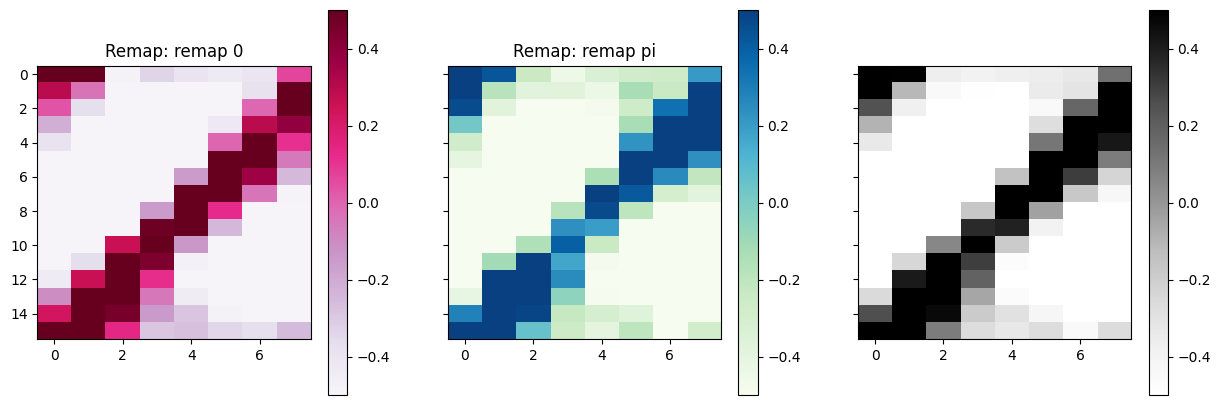

In [15]:
fig, ax = plt.subplots(1,3,figsize=[15,5],sharex=True,sharey=True)
h = ax[0].imshow(np.nanmean(opto_responses['remap_0deg'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='PuRd')
fig.colorbar(h, ax=ax[0])
h = ax[1].imshow(np.nanmean(opto_responses['remap_180deg'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='GnBu')
fig.colorbar(h, ax=ax[1])
h = ax[2].imshow(np.nanmean(opto_responses['combined'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='Greys')
fig.colorbar(h, ax=ax[2])

ax[0].set_title('Remap: remap 0')
ax[1].set_title('Remap: remap pi')


In [16]:
nonremap_sess_df = sess_df.loc[(sess_df['scan_type']=='baseline') | \
                               (sess_df['scan_type']=='post_0deg') | \
                               (sess_df['scan_type']=='post_180deg') | \
                               (sess_df['scan_type']=='post_novis1') | \
                               (sess_df['scan_type']=='post_novis2')]
flies = nonremap_sess_df['fly_id'].unique()
for index,row in nonremap_sess_df.iterrows():
    ts = nmp.session.GetTS(load_row(row))
    
    
    offset_c_mu = ts.offset_c.mean()
    
    sess_df.loc[index, 'mean offset'] = np.angle(offset_c_mu)
    sess_df.loc[index, 'mean vec. len'] = np.abs(offset_c_mu)
    sess_df.loc[index, 'offset var.'] = sp.stats.circvar(ts.offset)

/tmp/ipykernel_577279/1313351860.py:8: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.stripplot(data=tmp_sess_df, x='scan_type', y='mean vec. len', ax=ax, alpha=.5,


(0.0, 1.0)

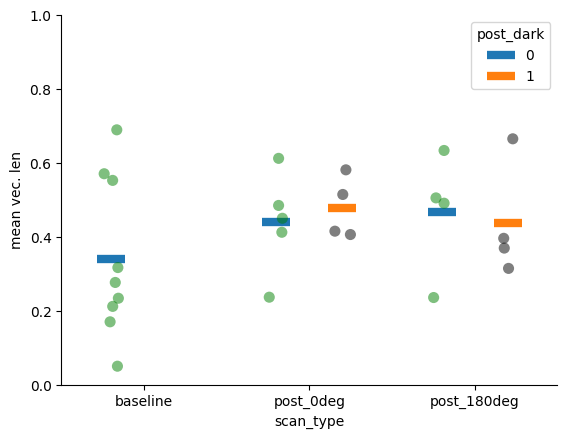

In [18]:
import seaborn as sns
fig, ax = plt.subplots()

colors = ['green', 'black', plt.cm.Greys(.6)]
tmp_sess_df = sess_df.loc[sess_df['scan_type'].isin(('baseline', 'post_0deg', 'post_180deg', 'post_novis1', 'post_novis2'))]
# tmp_sess_df = tmp_sess_df.loc[tmp_sess_df['condition'].isin(('remap', 'no_chrimson', 'novis_control'))]

sns.stripplot(data=tmp_sess_df, x='scan_type', y='mean vec. len', ax=ax, alpha=.5,
            dodge=True, palette=colors, hue='post_dark', s=8, legend=False,
            )
sns.pointplot(data=tmp_sess_df, x='scan_type', y='mean vec. len', ax=ax, 
              hue='post_dark',
              estimator=np.mean, errorbar=None, marker='_', markersize=20, 
              markeredgewidth=6, legend=True, dodge=.4, linestyle='none')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylim([0,1])
# fig.savefig(figfolder / "remapping_vec_len_comparison.pdf")


In [24]:
sess_df.loc[sess_df['fly_id']==flies[0]]

,date,fly,sess,fictrac_scan_num,fictrac_file,condition,scan_type,post_dark,usable,notes,fly_id,mean offset,offset var.,mean vec. len
0,22_04_2026,fly1,baseline-000,0,fictrac-20260422_101638.dat,replication,baseline,0,NaN,NaN,22_04_2026_fly1_replication,1.193090,0.447530,0.552470
1,22_04_2026,fly1,remap_0deg-002,2,fictrac-20260422_101638.dat,replication,remap_0deg,0,NaN,NaN,22_04_2026_fly1_replication,NaN,NaN,NaN
2,22_04_2026,fly1,post_0deg-004,4,fictrac-20260422_101638.dat,replication,post_0deg,0,NaN,NaN,22_04_2026_fly1_replication,-0.153364,0.550044,0.449956
3,22_04_2026,fly1,remap_180deg_wdark-005,5,fictrac-20260422_101638.dat,replication,remap_180deg,1,NaN,NaN,22_04_2026_fly1_replication,NaN,NaN,NaN
4,22_04_2026,fly1,post_180deg_wdark-006,6,fictrac-20260422_101638.dat,replication,post_180deg,1,NaN,NaN,22_04_2026_fly1_replication,-2.037667,0.604297,0.395703


In [19]:
def build_sum_stats(fly_list):
    sum_stats = {'fly_id': []}
    if not 'novis' in fly_list[0]:
        for s in ('baseline', 'post_0deg', 'post_180deg'):
            sum_stats[f'{s} mean offset'] = []
            sum_stats[f'{s} vec. len'] = []
            sum_stats[f'{s} offset var.'] = []
            
    else:
            
        for s in ('baseline', 'post_novis1', 'post_novis2'):
            sum_stats[f'{s} mean offset'] = []
            sum_stats[f'{s} vec. len'] = []
            sum_stats[f'{s} offset var.'] = []
                
    
    
    
    for fly in fly_list:
        sum_stats['fly_id'].append(fly)
        
        if not 'novis' in fly:
            for s in ('baseline', 'post_0deg', 'post_180deg'):
                sum_stats[f'{s} mean offset'].append(sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['scan_type']==s)]['mean offset'].mean())
                sum_stats[f'{s} vec. len'].append(sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['scan_type']==s)]['mean vec. len'].mean())
                sum_stats[f'{s} offset var.'].append(sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['scan_type']==s)]['offset var.'].mean())
        else:
            for s in ('baseline', 'post_novis1', 'post_novis2'):
                sum_stats[f'{s} mean offset'].append(sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['scan_type']==s)]['mean offset'].mean())
                sum_stats[f'{s} vec. len'].append(sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['scan_type']==s)]['mean vec. len'].mean())
                sum_stats[f'{s} offset var.'].append(sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['scan_type']==s)]['offset var.'].mean())
    return pd.DataFrame(sum_stats)                
        
    

In [20]:
flies

<ArrowStringArray>
['22_04_2026_fly1_replication', '22_04_2026_fly3_replication',
 '23_04_2026_fly1_replication', '23_04_2026_fly2_replication',
 '23_04_2026_fly3_replication', '27_04_2026_fly1_replication',
 '27_04_2026_fly2_replication', '27_04_2026_fly3_replication',
 '28_04_2026_fly1_replication']
Length: 9, dtype: str

In [21]:

sum_stats = build_sum_stats(flies)

In [22]:
def avg_diff(sum_stats):
    if not 'post_novis1 mean offset' in sum_stats.columns:
        diff0 = np.abs(sum_stats['post_0deg mean offset'] )
        diff180 = np.abs(np.pi - sum_stats['post_180deg mean offset'] )
        diff180 = np.minimum(diff180, 2*np.pi-diff180)
        
        
        
    else:
        diff0 = np.abs(sum_stats['post_novis1 mean offset'])
        diff0 = np.minimum(diff0, 2*np.pi-diff0)
        
        diff180 = np.abs(np.pi - sum_stats['post_novis2 mean offset'] )
        diff180 = np.minimum(diff180, 2*np.pi-diff180)
                
    return (diff0+diff180)/2

In [23]:
sum_stats

,fly_id,baseline mean offset,baseline vec. len,baseline offset var.,post_0deg mean offset,post_0deg vec. len,post_0deg offset var.,post_180deg mean offset,post_180deg vec. len,post_180deg offset var.
0,22_04_2026_fly1_replication,1.193090,0.552470,0.447530,-0.153364,0.449956,0.550044,-2.037667,0.395703,0.604297
1,22_04_2026_fly3_replication,0.071337,0.211577,0.788423,0.054692,0.581040,0.418960,-2.706180,0.505111,0.494889
2,23_04_2026_fly1_replication,-0.169944,0.570449,0.429551,0.158000,0.412126,0.587874,-2.826651,0.369304,0.630696
3,23_04_2026_fly2_replication,-0.347983,0.316593,0.683407,1.241410,0.415057,0.584943,-2.904473,0.490731,0.509269
4,23_04_2026_fly3_replication,1.948146,0.276321,0.723679,0.077468,0.236429,0.763571,1.852356,0.314354,0.685646
5,27_04_2026_fly1_replication,-1.300158,0.689269,0.310731,-0.622754,0.514364,0.485636,2.973668,0.633418,0.366582
6,27_04_2026_fly2_replication,-2.113391,0.233636,0.766364,0.607793,0.612076,0.387924,2.514115,0.664991,0.335009
7,27_04_2026_fly3_replication,-1.064669,0.169830,0.830170,-2.649346,0.405999,0.594001,-1.997108,0.235521,0.764479
8,28_04_2026_fly1_replication,0.387341,0.049722,0.950278,-0.356478,0.484699,0.515301,NaN,NaN,NaN
